In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_info_columns', 200)
pd.set_option('display.max_rows', None)

#use head() or DataWrangler for datasets to not crash IDE

In [5]:
df = pd.read_csv('data/train.csv', index_col='PassengerId')

## First look

In [6]:
df.head() 

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [25]:
target_col = 'Survived' # save it for later

In [7]:
df.shape

(891, 11)

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 111.9 KB


## Numerical and string/categorical columns

In [26]:
# Numerical cols
df.select_dtypes(include=['number']).info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Age       714 non-null    float64
 3   SibSp     891 non-null    int64  
 4   Parch     891 non-null    int64  
 5   Fare      891 non-null    float64
dtypes: float64(2), int64(4)
memory usage: 41.9 KB


In [27]:
# string columns
df.select_dtypes(include=['object']).info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Name      891 non-null    str  
 1   Sex       891 non-null    str  
 2   Ticket    891 non-null    str  
 3   Cabin     204 non-null    str  
 4   Embarked  889 non-null    str  
dtypes: str(5)
memory usage: 70.2 KB


C:\Users\admin\AppData\Local\Temp\ipykernel_21520\4267235047.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include=['object']).info()


In [28]:
# all unic values columns
unic = pd.DataFrame(df.nunique(dropna=False), columns=['nunique'])
unic[unic['nunique'] == len(df)].sort_values('nunique', ascending=False)

,nunique
Name,891


In [29]:
# truly categorical columns
unic = pd.DataFrame(df.nunique(dropna=False), columns=['nunique'])
unic[unic['nunique'] < 50].sort_values('nunique', ascending=False)

,nunique
Parch,7
SibSp,7
Embarked,4
Pclass,3
Survived,2
Sex,2


In [58]:
cat_features = unic[unic['nunique'] < 50].T.columns.to_list() # save it to list for later
cat_features.remove('Survived') # delete target column

num_features = df.drop(cat_features, axis=1).columns.to_list()
num_features.remove('Ticket')
num_features.remove('Cabin')
num_features.remove('Name') # all unic values


## Categorical features values distribution

In [36]:
for col in df[cat_features].columns:
    print(f"--- Top values for {col} ---")
    print(df[col].value_counts().head(10))

--- Top values for Pclass ---
Pclass
3    491
1    216
2    184
Name: count, dtype: int64
--- Top values for Sex ---
Sex
male      577
female    314
Name: count, dtype: int64
--- Top values for SibSp ---
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64
--- Top values for Parch ---
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64
--- Top values for Embarked ---
Embarked
S    644
C    168
Q     77
Name: count, dtype: int64


In [39]:
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0}) # map it to check correlations

## Correlations

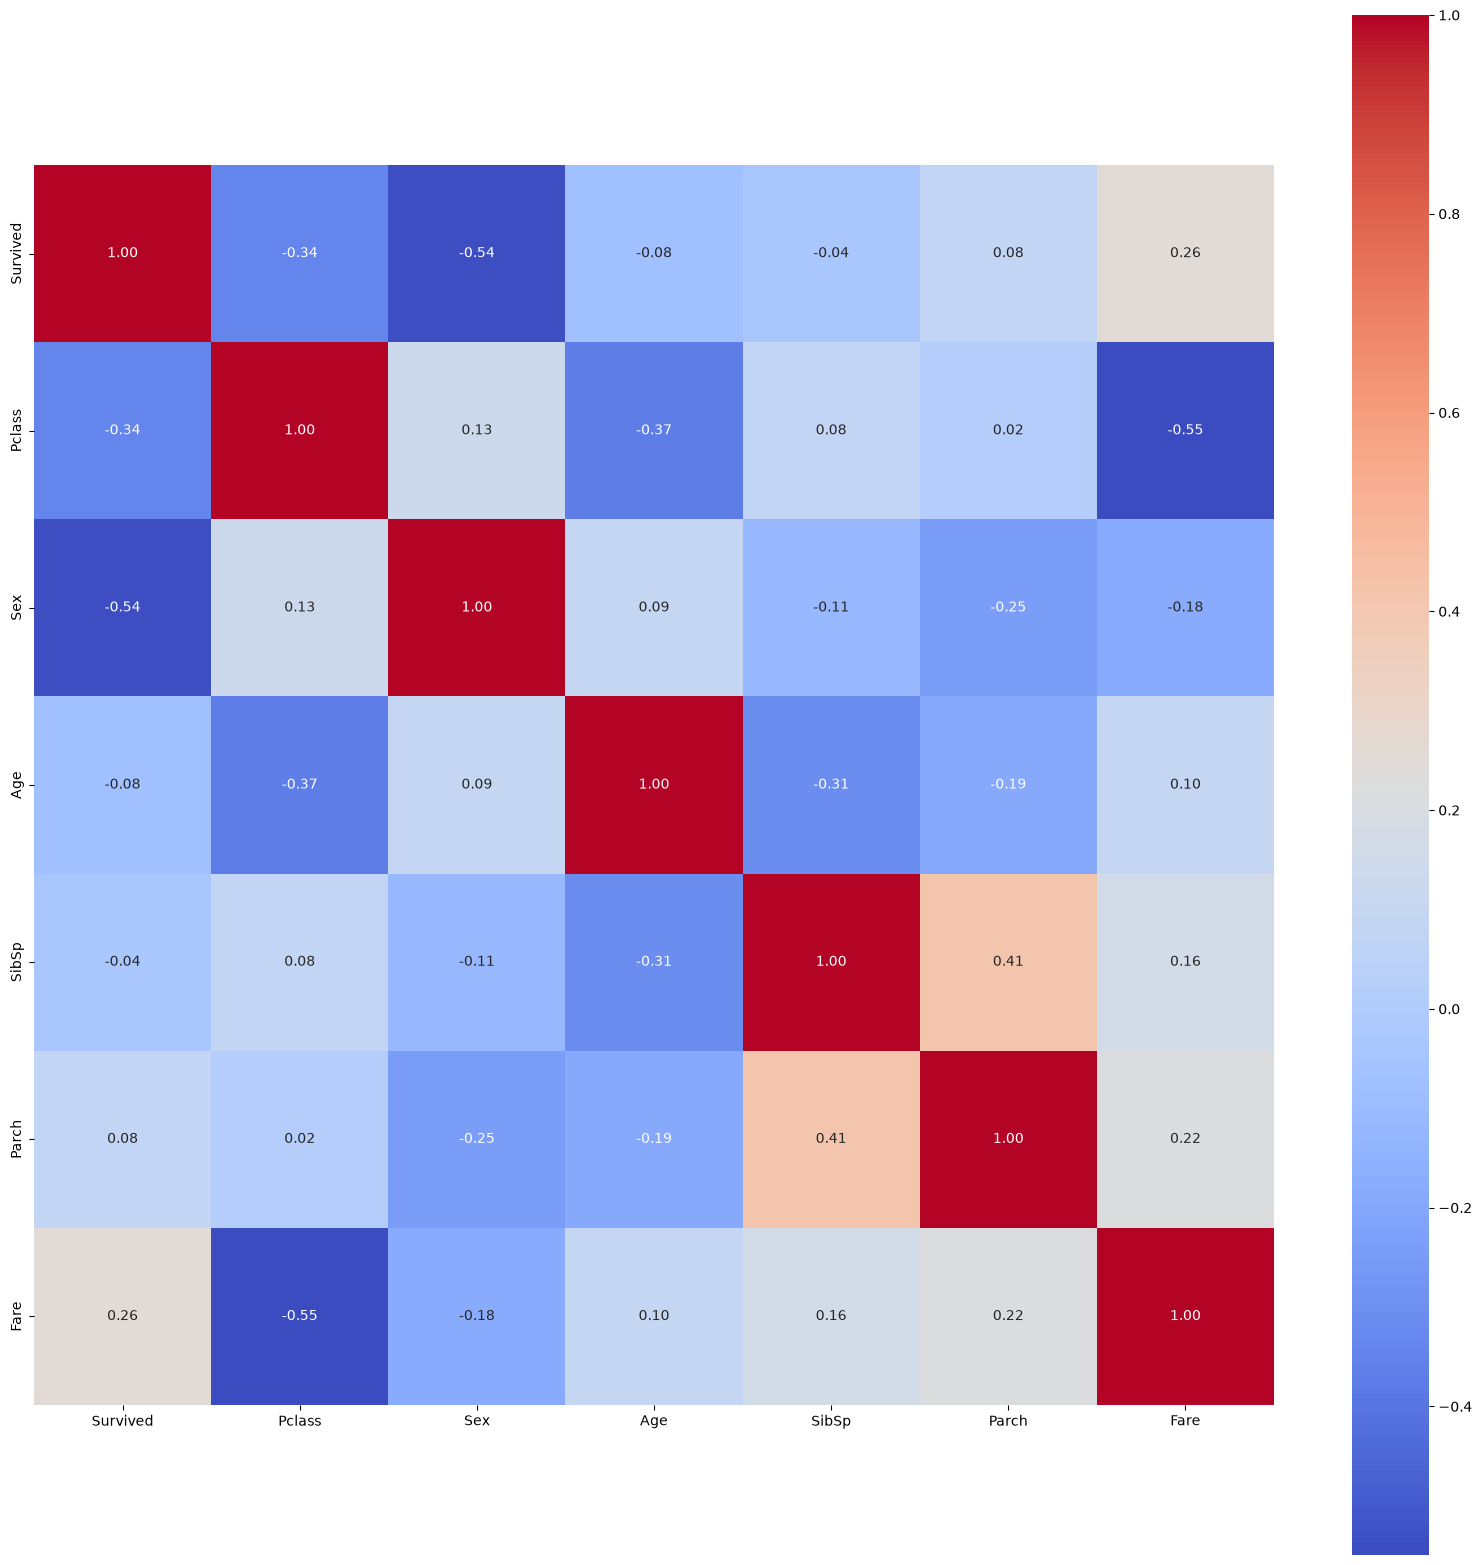

In [41]:
corr = df.select_dtypes(include=["number"]).corr()
plt.figure(figsize=(20, 20))
sns.heatmap(
    corr, 
    annot=True,      
    fmt=".2f",       
    cmap='coolwarm', 
    square=True      
)
plt.show()

In [42]:
corr[target_col].sort_values(ascending=False)

Survived    1.000000
Fare        0.257307
Parch       0.081629
SibSp      -0.035322
Age        -0.077221
Pclass     -0.338481
Sex        -0.543351
Name: Survived, dtype: float64

In [43]:
corr[target_col].sort_values(ascending=True)

Sex        -0.543351
Pclass     -0.338481
Age        -0.077221
SibSp      -0.035322
Parch       0.081629
Fare        0.257307
Survived    1.000000
Name: Survived, dtype: float64

Most correllating with survival: being female, 1 class/ticket price

## Missing values

In [44]:
df.isna().sum().sort_values(ascending = False)

Cabin       687
Age         177
Embarked      2
Name          0
Pclass        0
Survived      0
Sex           0
Parch         0
SibSp         0
Fare          0
Ticket        0
dtype: int64

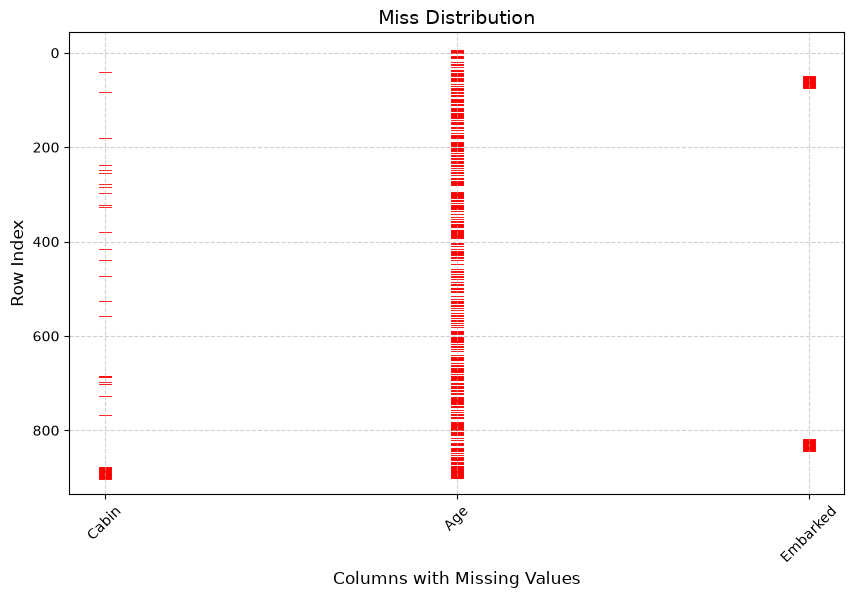

In [45]:
def plot_missing_data(df):    
    missing = df.isna().stack()
    missing_coords = missing[missing].reset_index()
    missing_coords.columns = ['Row', 'Column', 'Is_Missing']

    plt.figure(figsize=(10, 6))
    sns.scatterplot(
        data=missing_coords, 
        x='Column', 
        y='Row', 
        s=100,          
        color='red',    
        marker='s'      
    )

    plt.gca().invert_yaxis()

    plt.title('Miss Distribution', fontsize=14)
    plt.xlabel('Columns with Missing Values', fontsize=12)
    plt.xticks(rotation=45)
    plt.ylabel('Row Index', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)

    plt.show()

plot_missing_data(df)

In [47]:
df['Cabin'].value_counts(dropna=False)

Cabin
NaN                687
G6                   4
C23 C25 C27          4
B96 B98              4
F33                  3
E101                 3
F2                   3
D                    3
C22 C26              3
C123                 2
D33                  2
C52                  2
B28                  2
C83                  2
F G73                2
D26                  2
B58 B60              2
C2                   2
E33                  2
F4                   2
D36                  2
C93                  2
C78                  2
D35                  2
B77                  2
E67                  2
C125                 2
B49                  2
C65                  2
B57 B59 B63 B66      2
B18                  2
C124                 2
B35                  2
E44                  2
C92                  2
D20                  2
E25                  2
B22                  2
C68                  2
C126                 2
B51 B53 B55          2
B5                   2
B20                  2
E24  

We not gonna use Cabin, so not gonna fill it

In [48]:
df['Embarked'].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Fill it with most common

## Distributions

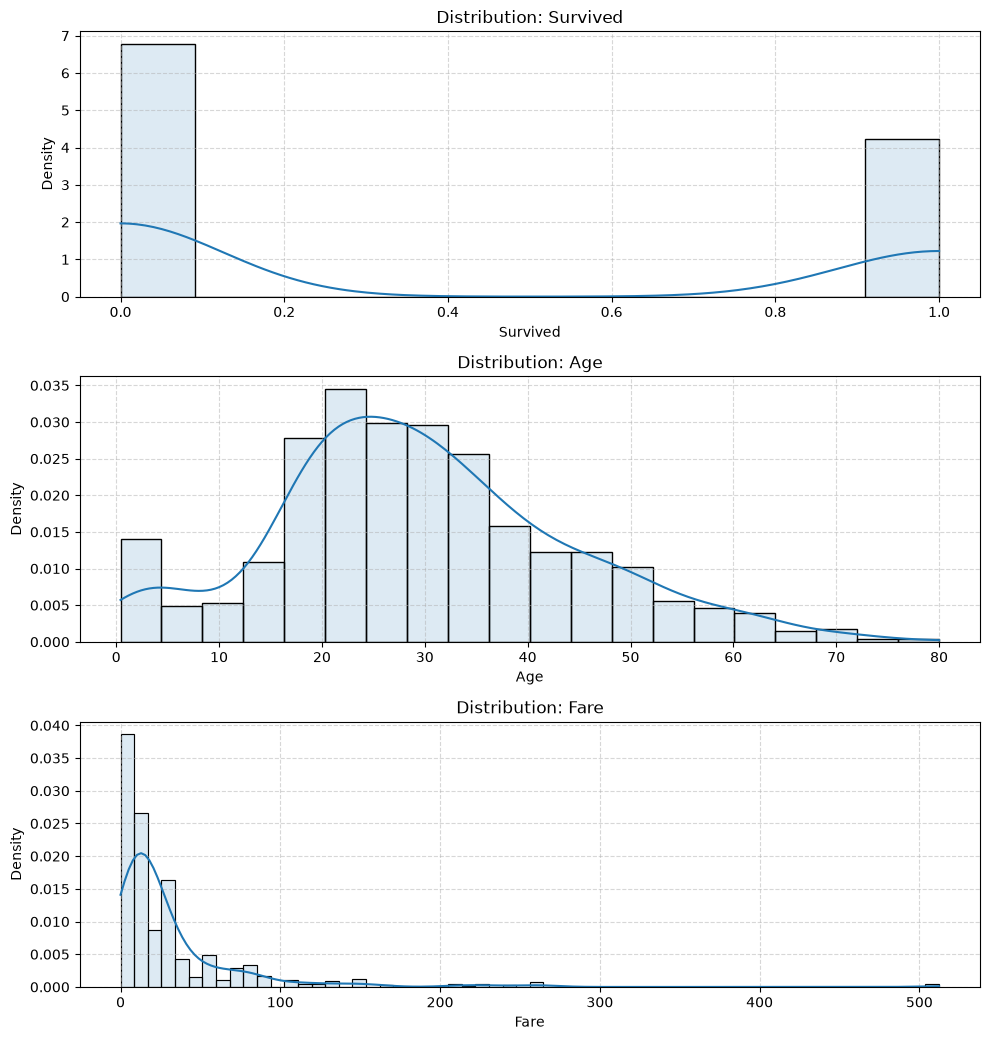

In [59]:
features_to_check = num_features

# plots code
fig, axes = plt.subplots(len(features_to_check), 1, figsize=(10, 3.5 * len(features_to_check)))

for ax, feature in zip(axes, features_to_check):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        common_norm=False,
        stat='density',
        fill=True,
        alpha=0.15,
        ax=ax
    )
    ax.set_title(f'Distribution: {feature}')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Age has almost normal distribution, so gonna fill it with median

In [60]:
def analyze_skewness(df, columns):
    recommendations = {}
    
    for col in columns:
        skewness = df[col].skew()
        has_negatives = (df[col] < 0).any()
        has_zeros = (df[col] == 0).any()
        
        print(f"\n{col}:")
        print(f"  Skewness: {skewness:.2f}")
        
        # recommendations
        if abs(skewness) < 0.5:
            print("StandardScaler - Normal distribution, no need for transformation")
            recommendations[col] = 'StandardScaler'
        elif abs(skewness) > 2:
            print("QuantileTransformer - Strong skewness, lot of outliers")
            recommendations[col] = 'QuantileTransformer'
        elif has_negatives or has_zeros:
            print(" PowerTransformer(yeo-johnson) - Has zeros/negatives")
            recommendations[col] = 'PowerTransformer(yeo-johnson)'
        else:
            print("PowerTransformer(box-cox) or log1p - Medium skewness")
            recommendations[col] = 'PowerTransformer(box-cox) or log1p'
    
    return recommendations

In [61]:
columns_to_check = num_features
recommendations = analyze_skewness(df, columns_to_check)


Survived:
  Skewness: 0.48
StandardScaler - Normal distribution, no need for transformation

Age:
  Skewness: 0.39
StandardScaler - Normal distribution, no need for transformation

Fare:
  Skewness: 4.79
QuantileTransformer - Strong skewness, lot of outliers


## Feature engineering

In [66]:
df['Initial']=df['Name'].str.extract('([A-Za-z]+)\.')

In [67]:
df['Initial'].value_counts(dropna=False)

Initial
Mr          517
Miss        182
Mrs         125
Master       40
Dr            7
Rev           6
Major         2
Mlle          2
Col           2
Don           1
Mme           1
Ms            1
Lady          1
Sir           1
Capt          1
Countess      1
Jonkheer      1
Name: count, dtype: int64

In [87]:
pd.crosstab(df['Initial'], df['Sex']).T

Initial,Master,Miss,Mr,Mrs,Other
Sex,,,,,
female,0,186,0,127,1
male,40,0,522,0,15


In [73]:
pd.crosstab(df['Initial'], df['Survived']).T

Initial,Capt,Col,Countess,Don,Dr,Jonkheer,Lady,Major,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir
Survived,,,,,,,,,,,,,,,,,
0,1,1,0,1,4,1,0,1,17,55,0,0,436,26,0,6,0
1,0,1,1,0,3,0,1,1,23,127,2,1,81,99,1,0,1


Just gonna put all categories from Dr to other categories

In [77]:
df['Initial'] = df['Initial'].replace(['Mlle','Mme','Ms','Dr','Major','Lady','Countess','Jonkheer','Col','Rev','Capt','Sir','Don'],['Miss','Miss','Miss','Other','Mr','Mrs','Mrs','Other','Other','Other','Mr','Mr','Mr'])

In [78]:
df['Initial'].value_counts()

Initial
Mr        529
Miss      186
Mrs       127
Master     40
Other       9
Name: count, dtype: int64

In [79]:
df.groupby('Initial')['Age'].mean() 

Initial
Master     4.574167
Miss      21.860000
Mr        32.739609
Mrs       35.981818
Other     45.888889
Name: Age, dtype: float64

In [85]:
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Master'), 'Age'] = 5
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Miss'), 'Age'] = 22
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Mr'), 'Age'] = 33
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Mrs'), 'Age'] = 36
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Other'), 'Age'] = 46

## Data Preparation pipeline


In [90]:
df = pd.read_csv('data/train.csv', index_col='PassengerId')
# stateless preprocessing #
df['Name'].fillna(' Mr.') # filling potential Name misses with most common initial
df['Initial']=df['Name'].str.extract('([A-Za-z]+)\.')
df['Initial'] = df['Initial'].replace(['Mlle','Mme','Ms','Dr','Major','Lady','Countess','Jonkheer','Col','Rev','Capt','Sir','Don'],['Miss','Miss','Miss','Other','Mr','Mrs','Mrs','Other','Other','Other','Mr','Mr','Mr'])
df = df.drop(['Name', 'Cabin', 'Ticket'], axis=1) # idk, how to use Cabin and Ticket
# Filling Age misses with mean value by initials
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Master'), 'Age'] = 5
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Miss'), 'Age'] = 22
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Mr'), 'Age'] = 33
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Mrs'), 'Age'] = 36
df.loc[(df['Age'].isnull()) & (df['Initial'] == 'Other'), 'Age'] = 46
# filling potential Sex misses by initial
df.loc[(df['Sex'].isnull()) & (df['Initial'] == 'Master'), 'Sex'] = 'male'
df.loc[(df['Sex'].isnull()) & (df['Initial'] == 'Miss'), 'Sex'] = 'female'
df.loc[(df['Sex'].isnull()) & (df['Initial'] == 'Mr'), 'Sex'] = 'male'
df.loc[(df['Sex'].isnull()) & (df['Initial'] == 'Mrs'), 'Sex'] = 'female'
df.loc[(df['Sex'].isnull()) & (df['Initial'] == 'Master'), 'Sex'] = 'male'
df.loc[(df['Sex'].isnull()) & (df['Initial'] == 'Other'), 'Sex'] = 'male' #in Other we have mostly males
# coding Sex
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})

Now we should choose strategy for filling misses to other columns

In [ ]:
fill_most_common_cols = ['Pclass', 'SibSp', 'Parch', 'Embarked']
fill_median_cols = ['Fare']

In [96]:
cat_features = ['Pclass', 'SibSp', 'Parch', 'Embarked', 'Sex', 'Initial'] # for target encoding
quantile_cols = ['Fare']